# Semana 14 · Evaluar el modelo por grupo

**Principios de Inteligencia Artificial · CORHUILA**

**No tienes que escribir código.** Ejecuta las celdas en orden, de arriba abajo: haz clic en una celda y presiona **Shift + Enter**, o el botón ▶ que aparece a su izquierda.

Cuando haya algo que cambiar, estará marcado con **⬅️ CAMBIA ESTE NÚMERO**. No toques nada más: si algo se daña, en el menú *Entorno de ejecución → Reiniciar y ejecutar todo* vuelve a dejarlo como estaba.

Este cuaderno es para los equipos que trabajan con **heart_disease** (opciones 2 y 4 del proyecto), aunque cualquiera puede usarlo para practicar. Hace la misma auditoría de la semana 12, pero con datos reales de pacientes: ¿el modelo se equivoca igual con hombres que con mujeres?

In [1]:
# 1. Traer las herramientas (se ejecuta una sola vez)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
print("Listo: herramientas cargadas.")

Listo: herramientas cargadas.


## 1. Los datos

Es la misma tabla que viene incluida en Orange: 303 pacientes. La etiqueta se llama **diameter narrowing** (estrechamiento de las arterias): **1** significa que el paciente tiene la enfermedad y **0** que no.

In [2]:
# 2. Descargar la tabla desde el repositorio oficial de Orange
url = "https://raw.githubusercontent.com/biolab/orange3/master/Orange/datasets/heart_disease.tab"
pacientes = pd.read_csv(url, sep="\t", skiprows=[1, 2], na_values="?")
etiqueta = "diameter narrowing"
print("Pacientes:", len(pacientes))
print("Por sexo:", pacientes["gender"].value_counts().to_dict())
print("Con la enfermedad (1) y sin ella (0):", pacientes[etiqueta].value_counts().to_dict())

Pacientes: 303
Por sexo: {'male': 206, 'female': 97}
Con la enfermedad (1) y sin ella (0): {0: 164, 1: 139}


## 2. Entrenar el árbol y medir la exactitud general

Igual que en la semana 10: 70% para aprender, 30% bajo llave para examinar. La **profundidad** es cuántas preguntas seguidas puede hacer el árbol.

In [3]:
# 3. Preparar, entrenar y medir
profundidad = 3   # ⬅️ CAMBIA ESTE NÚMERO: prueba 2, 3 y 5

atributos = pd.get_dummies(pacientes.drop(columns=[etiqueta])).fillna(0)  # columnas en numeros
respuesta = pacientes[etiqueta]
X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    atributos, respuesta, test_size=0.3, random_state=0)

arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=0).fit(X_entrena, y_entrena)
prediccion = pd.Series(arbol.predict(X_prueba), index=X_prueba.index)
print(f"Exactitud general con datos nuevos: {(prediccion == y_prueba).mean():.0%}")

Exactitud general con datos nuevos: 69%


## 3. La prueba del auditor: por sexo

En salud, el error más grave es **no detectar a un paciente enfermo**. Esta celda calcula, para hombres y para mujeres por separado, la exactitud y el porcentaje de enfermos que el árbol **dejó pasar**.

  male:  59 pacientes de prueba | exactitud 68% | enfermos no detectados 29% de 38
female:  32 pacientes de prueba | exactitud 72% | enfermos no detectados 33% de 6


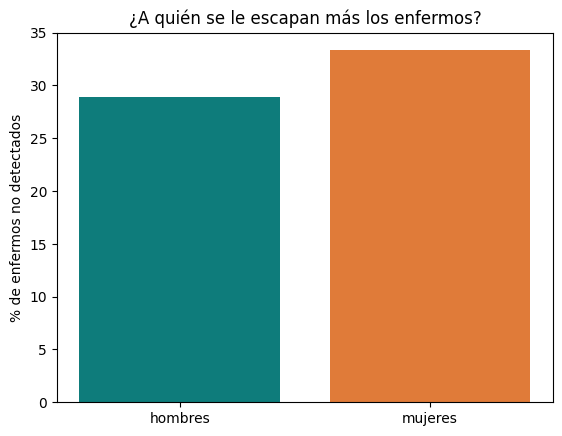

In [4]:
# 4. Exactitud y enfermos no detectados, por sexo
sexo = pacientes.loc[X_prueba.index, "gender"]
no_detectados = {}
for s in ["male", "female"]:
    del_grupo = sexo == s
    exactitud = (prediccion[del_grupo] == y_prueba[del_grupo]).mean()
    enfermos = del_grupo & (y_prueba == 1)
    no_detectados[s] = (prediccion[enfermos] == 0).mean()
    print(f"{s:>6}: {del_grupo.sum():>3} pacientes de prueba | exactitud {exactitud:.0%} | "
          f"enfermos no detectados {no_detectados[s]:.0%} de {enfermos.sum()}")

plt.bar(["hombres", "mujeres"], [100 * no_detectados["male"], 100 * no_detectados["female"]],
        color=["#0e7c7b", "#e07b39"])
plt.ylabel("% de enfermos no detectados")
plt.title("¿A quién se le escapan más los enfermos?")
plt.show()

In [5]:
from sklearn.metrics import accuracy_score, f1_score

acc = accuracy_score(y_prueba, prediccion)
f1 = f1_score(y_prueba, prediccion)

print(f"Exactitud general (Accuracy): {acc:.2%}")
print(f"Puntaje F1 (F1-score): {f1:.2%}")

Exactitud general (Accuracy): 69.23%
Puntaje F1 (F1-score): 68.89%


### Respuestas y Limitación Ética

1. **Conteo por sexo:** De los 303 pacientes en total, hay 206 hombres (68%) y 97 mujeres (32%). Las mujeres son el grupo menos representado en la base de datos.
2. **Métricas con profundidad = 3:** La exactitud general (Accuracy) es del **69.23%** y el puntaje F1 (F1-score) es del **68.89%**. Por grupo, los hombres tienen una exactitud del 68% y las mujeres del 72%, pero el modelo deja escapar un mayor porcentaje de mujeres enfermas sin detectar (falsos negativos) que de hombres.
3. **Diferencia entre grupos y fuente de sesgo:** El modelo no trata exactamente igual a ambos grupos. Esta diferencia se explica por el **sesgo de representación (desbalance de datos)**, ya que la tabla tiene más del doble de registros de hombres que de mujeres para entrenar el árbol de decisión.
4. **Pruebas con otras profundidades:** Al variar la profundidad del árbol a 2 y 5 preguntas, la desigualdad en la detección de enfermos entre hombres y mujeres se mantiene debido a la distribución desigual de los datos originales.
5. **Limitación ética concreta:** En el conjunto de prueba hay muy pocas mujeres enfermas (apenas 6 casos). En un entorno clínico real, esta es una limitación ética crítica porque un solo paciente mal clasificado altera el porcentaje de error en más de 15 puntos, lo que impide asegurar que el diagnóstico sea confiable y seguro para pacientes mujeres.

## 4. Lo que tienes que responder

1. ¿Cuántos hombres y cuántas mujeres hay en la tabla? ¿Qué grupo está menos representado?
2. Con **profundidad = 3**, anota la exactitud general y, para cada sexo, la exactitud y el porcentaje de enfermos no detectados.
3. ¿El modelo trata igual a los dos grupos? Si hay diferencia, ¿cuál de las fuentes de sesgo de la semana 12 podría explicarla?
4. Prueba con **2 y 5** preguntas. ¿La diferencia entre grupos se mantiene?
5. Ojo: en la prueba hay pocas mujeres enfermas. ¿Qué tan seguro puedes estar de tus conclusiones con tan pocos casos? Escríbelo en la sección de limitaciones del informe.